In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os
os.chdir('/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO')
CWD_PATH = os.getcwd()
print(CWD_PATH)

/content/drive/My Drive/colab/CSC6502 - Computer Vision/cv_practical_work/csc6502-prac6-CHIPOMPO


### Task 3. Calibrate your own camera

In [3]:
#!pip install -q opencv-contrib-python

import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Image as IPImage
import glob
#%pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless opencv-contrib-python-headless
#%pip install opencv-python

In [4]:
##############################################
# CONFIGURATION
##############################################

# Folder containing chessboard photos.
IMAGE_DIR = "images/calibration_photos"

# Chessboard dimensions — counting the INNER corners
CHESSBOARD_COLS = 7
CHESSBOARD_ROWS = 7

# Real-world size of one square in millimetres.
SQUARE_SIZE_MM = 20.0

# Sensor spec (used to convert focal length from pixels to mm).
#  phone's sensor width in mm.
SENSOR_WIDTH_MM = 8.16

# Which image to undistort for the before/after demo (index into the
# successfully-detected list). Choose one with strong straight lines
# near the edges if possible — a wall, floor tiles, or the board itself.
DEMO_IMAGE_INDEX = 0

In [5]:
# ##############################################
# LOAD IMAGES
##############################################

image_paths = sorted(
    glob.glob(f"{IMAGE_DIR}/*.jpg")
)

if not image_paths:
    raise FileNotFoundError(
        f"No images found in {IMAGE_DIR}. "
        "Upload your chessboard photos there first."
    )

print(f"Found {len(image_paths)} candidate images.")
for p in image_paths[:5]:
    print(" ", Path(p).name)
if len(image_paths) > 5:
    print(f"  ... and {len(image_paths) - 5} more.")

Found 19 candidate images.
  20261012_150547.jpg
  20261012_150551.jpg
  20261012_150559.jpg
  20261012_150630.jpg
  20261012_150642.jpg
  ... and 14 more.


In [ ]:
##############################################
# DETECT CHESSBOARD CORNERS
##############################################

# Termination criteria for corner sub-pixel refinement.
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
            30, 1e-3)

# Prepare the 3D coordinates of the chessboard corners in object space.
# Z = 0 since the board is planar. Units: millimetres.
objp = np.zeros((CHESSBOARD_ROWS * CHESSBOARD_COLS, 3),
                np.float32)
objp[:, :2] = np.mgrid[
    0:CHESSBOARD_COLS, 0:CHESSBOARD_ROWS
].T.reshape(-1, 2)
objp *= SQUARE_SIZE_MM

objpoints = []   # 3D points in real world space
imgpoints = []   # 2D points in image plane
image_size = None
good_paths = []
bad_paths = []

for path in image_paths:
    img = cv2.imread(path)
    if img is None:
        bad_paths.append((path, "unreadable"))
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    if image_size is None:
        image_size = (gray.shape[1], gray.shape[0])
    elif (gray.shape[1], gray.shape[0]) != image_size:
        # Skip images of a different resolution — mixing sizes
        # breaks calibration unless  rescaled.
        bad_paths.append((path, "size mismatch"))
        continue

    # Try to detect the full inner-corner grid.
    ret, corners = cv2.findChessboardCorners(
        gray,
        (CHESSBOARD_COLS, CHESSBOARD_ROWS),
        flags=cv2.CALIB_CB_ADAPTIVE_THRESH
            + cv2.CALIB_CB_NORMALIZE_IMAGE
            + cv2.CALIB_CB_FAST_CHECK
    )

    if not ret:
        bad_paths.append((path, "no chessboard found"))
        continue

    # Sub-pixel refinement for precision.
    corners_refined = cv2.cornerSubPix(
        gray, corners, (11, 11), (-1, -1), criteria
    )

    objpoints.append(objp)
    imgpoints.append(corners_refined)
    good_paths.append(path)

print(f"\nSuccessfully detected corners in "
      f"{len(good_paths)}/{len(image_paths)} images.")
print(f"Image size: {image_size[0]} x {image_size[1]} px\n")

if bad_paths:
    print("Rejected images:")
    for p, reason in bad_paths:
        print(f"  {Path(p).name}: {reason}")

if len(good_paths) < 6:
    print("\n⚠ Fewer than 6 valid images. Calibration may be unstable. "
          "Retake more photos with varied poses.")


Successfully detected corners in 19/19 images.
Image size: 3000 x 4000 px



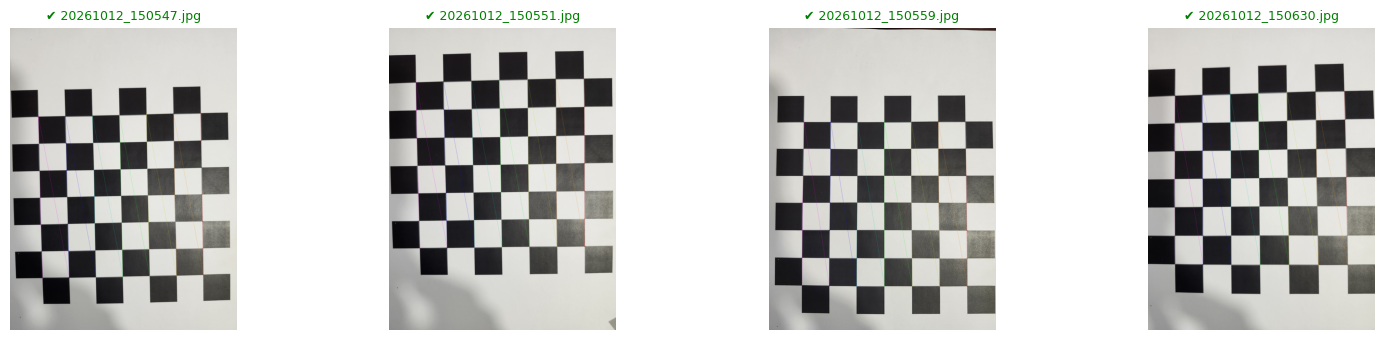

Detected board in 4/4 of the displayed images.


In [ ]:


n_show = min(4, len(image_paths))
if n_show == 0:
    print("No images to show.")
else:
    cols = 4
    rows = (n_show + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    axes = axes.flatten()

    for i in range(n_show):
        path = image_paths[i]
        img = cv2.imread(path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        ret, corners = cv2.findChessboardCorners(
            gray,
            (CHESSBOARD_COLS, CHESSBOARD_ROWS),
            flags=cv2.CALIB_CB_ADAPTIVE_THRESH
                + cv2.CALIB_CB_NORMALIZE_IMAGE
        )

        if ret:
            corners = cv2.cornerSubPix(gray, corners, (11, 11),
                                       (-1, -1), criteria)
            vis = cv2.drawChessboardCorners(
                img.copy(),
                (CHESSBOARD_COLS, CHESSBOARD_ROWS),
                corners, ret
            )
            title_colour = "green"
            title = f"✔ {Path(path).name}"
        else:
            vis = img
            title_colour = "red"
            title = f"✘ {Path(path).name} — not found"

        axes[i].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        axes[i].set_title(title, fontsize=9, color=title_colour)
        axes[i].axis("off")

    # Hide any unused subplots
    for j in range(n_show, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

    # Also print a summary
    n_ok = sum(
        1 for p in image_paths[:n_show]
        if cv2.findChessboardCorners(
            cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2GRAY),
            (CHESSBOARD_COLS, CHESSBOARD_ROWS),
            flags=cv2.CALIB_CB_ADAPTIVE_THRESH
                + cv2.CALIB_CB_NORMALIZE_IMAGE
        )[0]
    )
    print(f"Detected board in {n_ok}/{n_show} of the displayed images.")

In [ ]:
##############################################
# CALIBRATION
##############################################

ret, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None
)

if not ret:
    raise RuntimeError("Calibration failed.")

print("=" * 60)
print("CALIBRATION RESULT")
print("=" * 60)

print(f"\nCamera matrix K (3x3):\n{K}\n")

fx = K[0, 0]
fy = K[1, 1]
cx = K[0, 2]
cy = K[1, 2]

print(f"fx = {fx:.3f} px")
print(f"fy = {fy:.3f} px")
print(f"cx = {cx:.3f} px  (principal point)")
print(f"cy = {cy:.3f} px")

print(f"\nDistortion coefficients (k1, k2, p1, p2, k3):")
print(f"  {dist.ravel()}")

# RMS reprojection error
mean_error = 0.0
per_image_errors = []
mean_error = 0.0
per_image_errors = []

for i in range(len(objpoints)):
    imgpoints_proj, _ = cv2.projectPoints(
        objpoints[i], rvecs[i], tvecs[i], K, dist
    )

    # Reshape both to (N, 2) so cv2.norm sees matching types.
    pts_actual = imgpoints[i].reshape(-1, 2).astype(np.float32)
    pts_proj   = imgpoints_proj.reshape(-1, 2).astype(np.float32)

    err = cv2.norm(pts_actual, pts_proj, cv2.NORM_L2) / len(pts_proj)
    per_image_errors.append(err)
    mean_error += err

mean_error /= len(objpoints)
per_image_errors = np.array(per_image_errors)

print(f"\nRMS reprojection error (calibrateCamera): {ret:.4f} px")
print(f"Mean per-image reprojection error:         {mean_error:.4f} px")
print(f"Min / Max per-image error:                 "
      f"{per_image_errors.min():.4f} / "
      f"{per_image_errors.max():.4f} px")

if ret < 1.0:
    print("\n✔ RMS < 1 px — good calibration.")
elif ret < 2.0:
    print("\n~ RMS between 1 and 2 px — acceptable but could be better.")
else:
    print("\n✘ RMS > 2 px — consider retaking photos with "
          "better lighting, sharper focus, and more varied poses.")

# Which images have the highest per-image error?
worst_idx = np.argsort(per_image_errors)[::-1][:5]
print("\nHighest-error images (candidates to drop):")
for idx in worst_idx:
    print(f"  {Path(good_paths[idx]).name:40s}  "
          f"{per_image_errors[idx]:.4f} px")

CALIBRATION RESULT

Camera matrix K (3x3):
[[2.82819686e+03 0.00000000e+00 1.53004752e+03]
 [0.00000000e+00 2.83122865e+03 2.00296263e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]

fx = 2828.197 px
fy = 2831.229 px
cx = 1530.048 px  (principal point)
cy = 2002.963 px

Distortion coefficients (k1, k2, p1, p2, k3):
  [ 0.13209791 -0.44242192  0.0006959   0.00140488  0.40070856]

RMS reprojection error (calibrateCamera): 1.5820 px
Mean per-image reprojection error:         0.2251 px
Min / Max per-image error:                 0.1747 / 0.2807 px

~ RMS between 1 and 2 px — acceptable but could be better.

Highest-error images (candidates to drop):
  20261012_150630.jpg                       0.2807 px
  20261012_150551.jpg                       0.2524 px
  20261012_152230.jpg                       0.2400 px
  20261012_150654.jpg                       0.2370 px
  20261012_152411.jpg                       0.2330 px


In [ ]:
##############################################
# CONVERTING FOCAL LENGTH FROM PIXELS TO MILLIMETRES
##############################################

img_width_px = image_size[0]
mm_per_pixel = SENSOR_WIDTH_MM / img_width_px

focal_px_avg = (fx + fy) / 2.0
focal_mm = focal_px_avg * mm_per_pixel

# Horizontal and vertical field of view (approximate, ignoring distortion)
fov_x_deg = 2 * np.degrees(np.arctan(img_width_px / (2 * fx)))
fov_y_deg = 2 * np.degrees(
    np.arctan(image_size[1] / (2 * fy))
)

print("=" * 60)
print("FOCAL LENGTH")
print("=" * 60)
print(f"Sensor width (spec)      : {SENSOR_WIDTH_MM} mm")
print(f"Image width              : {img_width_px} px")
print(f"mm per pixel             : {mm_per_pixel:.6f} mm/px")
print(f"\nfx = {fx:.2f} px   fy = {fy:.2f} px")
print(f"Focal length (avg)       : {focal_px_avg:.2f} px")
print(f"Focal length             : {focal_mm:.3f} mm")
print(f"\nApprox. horizontal FOV   : {fov_x_deg:.2f}°")
print(f"Approx. vertical FOV     : {fov_y_deg:.2f}°")

# Sanity check
if 2.5 <= focal_mm <= 12.0:
    print("\n✔ Focal length is in the typical range for a phone "
          "wide-angle lens.")
else:
    print("\n⚠ Focal length is unusual for a phone camera. "
          "Double-check your sensor spec, or your calibration "
          "may be off.")

FOCAL LENGTH
Sensor width (spec)      : 8.16 mm
Image width              : 3000 px
mm per pixel             : 0.002720 mm/px

fx = 2828.20 px   fy = 2831.23 px
Focal length (avg)       : 2829.71 px
Focal length             : 7.697 mm

Approx. horizontal FOV   : 55.88°
Approx. vertical FOV     : 70.48°

✔ Focal length is in the typical range for a phone wide-angle lens.


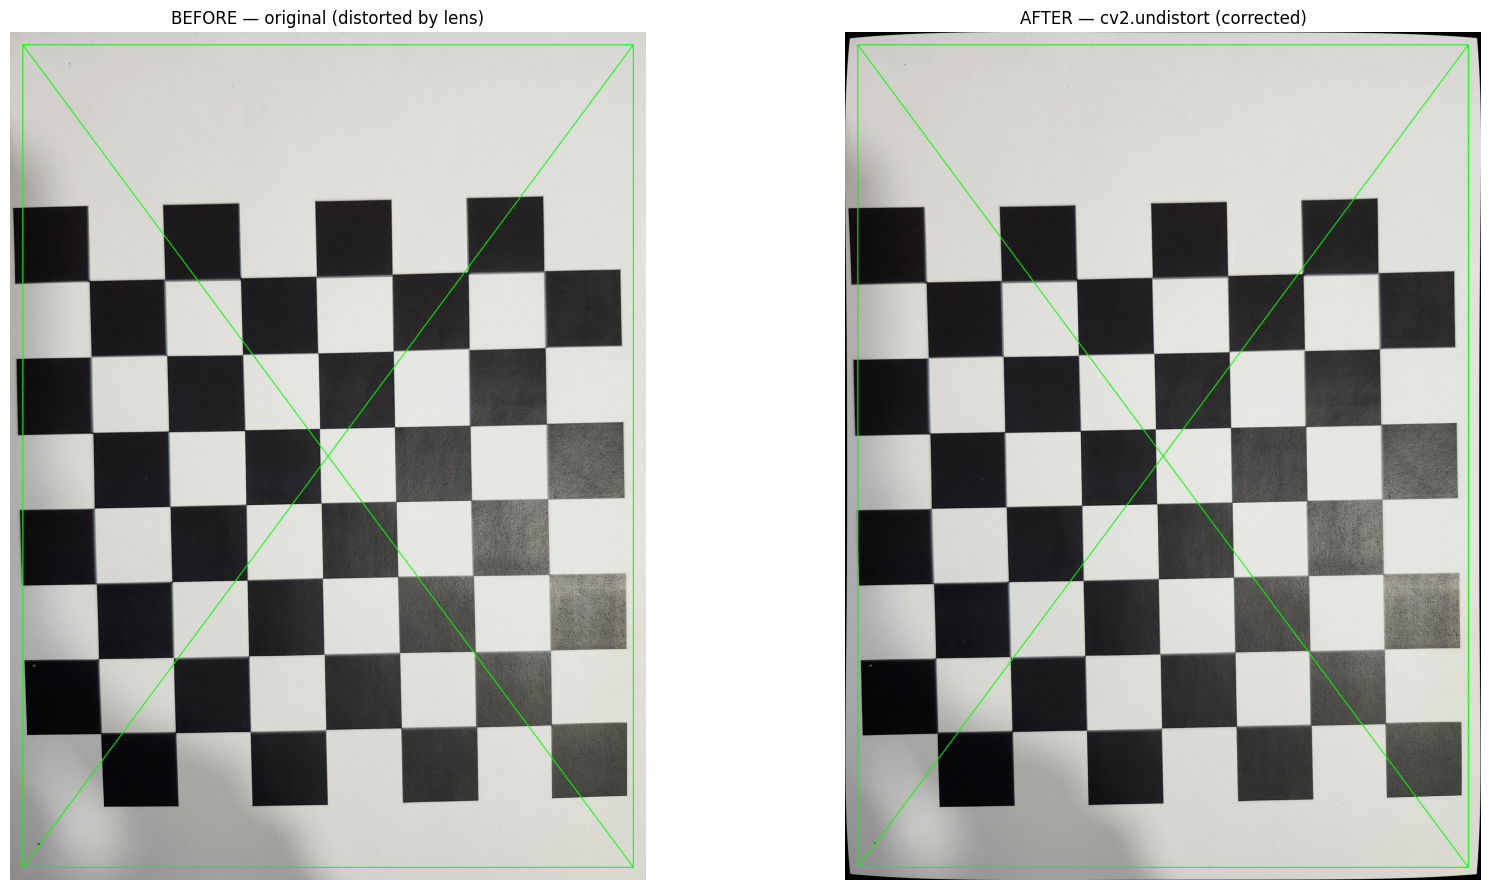

Demo image: 20261012_150547.jpg
Saved side-by-side to images/calibration_photos/undistort_before_after/undistort_before_after.png


In [ ]:
##############################################
# UNDISTORT A DEMO IMAGE
##############################################


# Choose which image to undistort — index into good_paths
DEMO_INDEX = 0
demo_path = good_paths[DEMO_INDEX]
demo_img = cv2.imread(demo_path)

h, w = demo_img.shape[:2]

# OpenCV 5.x uses newImgSize (4.x used newSize).
# If you ever downgrade to 4.x, swap this back.
new_K, roi = cv2.getOptimalNewCameraMatrix(
    K, dist, (w, h), alpha=1, newImgSize=(w, h)
)

# The actual undistortion.
undistorted = cv2.undistort(demo_img, K, dist, None, new_K)

# Draw straight reference lines on both, so distortion is obvious
def draw_reference_lines(img):
    out = img.copy()
    h_, w_ = out.shape[:2]
    colour = (0, 255, 0)      # green in BGR
    thickness = max(2, w_ // 800)
    margin = int(min(h_, w_) * 0.02)

    cv2.rectangle(out, (margin, margin),
                  (w_ - margin, h_ - margin), colour, thickness)
    cv2.line(out, (margin, margin), (w_ - margin, h_ - margin),
             colour, thickness)
    cv2.line(out, (w_ - margin, margin), (margin, h_ - margin),
             colour, thickness)
    return out

before_vis = draw_reference_lines(demo_img)
after_vis  = draw_reference_lines(undistorted)

# Side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

axes[0].imshow(cv2.cvtColor(before_vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("BEFORE — original (distorted by lens)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(after_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("AFTER — cv2.undistort (corrected)", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.savefig("images/calibration_photos/undistort_before_after/undistort_before_after.png",
            dpi=140, bbox_inches="tight")
plt.show()

cv2.imwrite("images/calibration_photos/undistort_before_after/undistort_before.jpg", before_vis)
cv2.imwrite("images/calibration_photos/undistort_before_after/undistort_after.jpg",  after_vis)

print(f"Demo image: {Path(demo_path).name}")
print("Saved side-by-side to images/calibration_photos/undistort_before_after/undistort_before_after.png")

In [ ]:
##############################################
# SAVE CALIBRATION FOR REUSE
##############################################

calib_file = Path("images/calibration.npz")
np.savez(
    calib_file,
    K=K,
    dist=dist,
    image_size=np.array(image_size),
    fx=fx, fy=fy, cx=cx, cy=cy,
    focal_mm=focal_mm,
    sensor_width_mm=SENSOR_WIDTH_MM,
    rms=ret,
)

print(f"Saved: {calib_file}")

# Example of loading it later:
#
# data = np.load("/content/calibration.npz")
# K = data["K"]; dist = data["dist"]
# und = cv2.undistort(img, K, dist)

Saved: images/calibration.npz
